# 09 · Phase 4: Failure Mode & Clinical Error Audit

We study **where and why** the Phase 2 classifier (EfficientNet-B0, `nb06crops_weighted`, high-sensitivity threshold) makes mistakes. Following the sprint plan we:
- **p4-t1:** group false positives (FP) and false negatives (FN) by view, brightness/contrast and shadowing (sections 3, 6);
- **p4-t2:** check how segmentation failures and conflicting labels (images 4 and 296) carry over into classification and Grad-CAM (sections 4, 7, 8);
- **p4-t3:** build a success vs. failure figure (section 9);
- summarise everything in an error taxonomy (section 10) and conclusions with clinical notes (section 11).

All tables and figures are saved in `results/phase4_error_audit/`.

## Methods

**Data used.** Phase 2 out-of-fold predictions and models (`results/phase2_classifier/`), Phase 1 crops and crop quality (`crop_audit.csv`, `lesion_crop_coverage.csv`, `oof_kidney_crops/`), Phase 3 Grad-CAM metrics (`results/phase3_xai/`), the doctors' labels (`bbdd_kidney/labels/`) and the duplicate pairs from the EDA (`results/eda/duplicate_pairs.csv`).

**Key terms**
- **Out-of-fold:** each image is predicted by the fold model that never saw it in training, so the errors are honest. No model is trained here.
- **TP / TN / FP / FN:** correct pathological / correct healthy / healthy called pathological (false alarm) / pathological called healthy (missed).
- **Sensitivity** = TP / (TP + FN): share of pathological kidneys detected. **Specificity** = TN / (TN + FP): share of healthy kidneys called healthy. We use them instead of accuracy because the data are imbalanced (450 healthy, 1,535 pathological).
- **Margin** = probability − threshold. Positive means "predicted pathological"; the further from 0, the more confident the model.
- **Dice** = 2·|A∩B| / (|A| + |B|) between the Phase 1 kidney mask and the doctor's mask (0 = no overlap, 1 = perfect). We use it as crop quality.
- **Brightness / contrast / shadow:** mean, standard deviation and share of very dark pixels (< 20) in the lower half of the grey-scale crop.
- **Grad-CAM:** heat map of the parts of the crop that pushed the model towards "pathological". From Phase 3 we use, for the fold model that made each prediction: **kidney focus** (share of the strongest pixels inside the kidney mask), **peak in kidney**, and **peak on / within 10 px of a lesion box**. Empty maps (no evidence at all) are counted apart.

**Limitations.** No confidence intervals or statistical tests, so small groups (e.g. 11 solid renal masses, 143 images in view 1) may differ by chance. The taxonomy cut-offs are our choice. The shadow measure is approximate and lesion size is in pixels. Grad-CAM shows where the model looks, not why, and its 7×7 grid is coarse. All findings are associations, not proven causes.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
P2   = ROOT / 'results/phase2_classifier'
P3   = ROOT / 'results/phase3_xai'
OUT  = ROOT / 'results/phase4_error_audit'
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 160)

## 1. Data

We join the predictions, crop information and the doctors' labels (lesion types, number and size of lesions) into one table, `df`, with one row per image. Lesion names follow the team's code (`src/kidney/config.py`): 1 LIT stone, 2 SCY simple cyst, 3 CCY complicated cyst, 4 PYR pyramids, 5 ANG angiomyolipoma, 6 SRM solid renal mass, 7 HYD hydronephrosis, 8 CT cortex thinning, 9 CE cortex eschar. The two global pathologies are PCD and HC (`src/kidney/data.py`).

In [2]:
pred  = pd.read_csv(P2 / 'nb06crops_weighted/imagenet/oof_predictions.csv')
audit = pd.read_csv(P2 / 'crop_audit.csv')[['image_id','view','dice','kidney_coverage','crop_x0','crop_y0','crop_x1','crop_y1']]
lcov  = pd.read_csv(P2 / 'lesion_crop_coverage.csv')

def parse_label(p):
    g, boxes = (0, 0), []
    for line in p.read_text().splitlines():
        if line.startswith('Global pathologies'):
            g = tuple(int(x) for x in line.split(':')[1].split())
        elif line.startswith('Bounding box'):
            boxes.append([int(x) for x in line.split(':')[1].split()])
    return g, boxes

rows = []
for p in (ROOT / 'bbdd_kidney/labels').glob('*.txt'):
    g, boxes = parse_label(p)
    rows.append(dict(image_id=int(p.stem), pcd=g[0], hc=g[1], n_lesions=len(boxes),
                     lesion_classes=sorted({b[4] for b in boxes}),
                     min_lesion_area=min((b[2]*b[3] for b in boxes), default=np.nan)))
lab = pd.DataFrame(rows)

df = pred.merge(audit, on='image_id').merge(lab, on='image_id')
df['error']  = df.outcome.isin(['FP','FN'])
df['margin'] = df.probability - df.threshold
print(df.shape)
df.outcome.value_counts()

(1985, 27)


outcome
TP    1373
TN     237
FP     213
FN     162
Name: count, dtype: int64

In [3]:
CLASS_NAMES = {1: 'LIT (stone)', 2: 'SCY (simple cyst)', 3: 'CCY (complicated cyst)', 4: 'PYR (pyramids)',
               5: 'ANG (angiomyolipoma)', 6: 'SRM (solid renal mass)', 7: 'HYD (hydronephrosis)',
               8: 'CT (cortex thinning)', 9: 'CE (cortex eschar)'}
GLOBAL_NAMES = {'pcd': 'PCD (poor corticomedullary distinction)', 'hc': 'HC (hyper-echoic cortex)'}

## 2. Overall summary

`rates()` computes TP, TN, FP, FN, sensitivity and specificity for any group of images.

In [4]:
def rates(d):
    tp, tn, fp, fn = [(d.outcome == k).sum() for k in ['TP','TN','FP','FN']]
    return pd.Series(dict(n=len(d), TP=tp, TN=tn, FP=fp, FN=fn,
        sensitivity=tp/(tp+fn) if tp+fn else np.nan,
        specificity=tn/(tn+fp) if tn+fp else np.nan,
        error_rate=(fp+fn)/len(d)))
rates(df).to_frame('overall').T.round(3)

,n,TP,TN,FP,FN,sensitivity,specificity,error_rate
overall,1985.0,1373.0,237.0,213.0,162.0,0.894,0.527,0.189


Sensitivity is high (**0.894**) and specificity low (**0.527**): 375 errors in total (162 FN, 213 FP). This is the intended trade-off of the high-sensitivity threshold, since missing a sick kidney is worse than an extra referral.

## 3. Errors by view (p4-t1)

View 0 is transverse (1,842 images) and view 1 longitudinal (143), as in `src/kidney/data.py` and the URI-CADS paper (93% / 7%).

In [5]:
by_view = df.groupby('view').apply(rates, include_groups=False).round(3)
by_view.to_csv(OUT / 'errors_by_view.csv'); by_view

,n,TP,TN,FP,FN,sensitivity,specificity,error_rate
view,,,,,,,,
0,1842.0,1293.0,203.0,193.0,153.0,0.894,0.513,0.188
1,143.0,80.0,34.0,20.0,9.0,0.899,0.630,0.203


Sensitivity is the same in both views (0.894 vs 0.899) and specificity is not worse in view 1 (0.63 vs 0.51, but only 54 healthy images). **The view does not affect the classifier.**

## 4. Errors by crop quality (p4-t2)

The classifier only sees the Phase 1 crop, so a poor segmentation (low Dice) could cause errors.

In [6]:
df['dice_group'] = pd.cut(df.dice, [-0.01, 0.80, 0.90, 0.95, 1.0], labels=['<0.80','0.80–0.90','0.90–0.95','≥0.95'])
by_dice = df.groupby('dice_group', observed=True).apply(rates, include_groups=False).round(3)
by_dice.to_csv(OUT / 'errors_by_crop_dice.csv'); by_dice

,n,TP,TN,FP,FN,sensitivity,specificity,error_rate
dice_group,,,,,,,,
<0.80,89.0,76.0,4.0,3.0,6.0,0.927,0.571,0.101
0.80–0.90,329.0,257.0,25.0,28.0,19.0,0.931,0.472,0.143
0.90–0.95,712.0,513.0,75.0,74.0,50.0,0.911,0.503,0.174
≥0.95,855.0,527.0,133.0,108.0,87.0,0.858,0.552,0.228


- Poor crops do **not** cause more missed kidneys: sensitivity is 0.93 for Dice < 0.80, the same as the middle groups, and only 9 errors happen there.
- Sensitivity is lowest for the best crops (0.86 for Dice ≥ 0.95). The mix of global pathologies and lesion types does not explain this; one untested idea is that easy-to-segment kidneys look more normal, so their lesions are more subtle.
- The error-rate column is not a fair comparison: poor crops contain very few healthy images (7 of 89), and healthy images cause many false positives.

The 10 worst-segmented images:

In [7]:
worst_seg = df.nsmallest(10, 'dice')[['image_id','view','dice','kidney_coverage','true_label','probability','threshold','outcome']]
worst_seg.to_csv(OUT / 'worst_segmentation_cases.csv', index=False); worst_seg

,image_id,view,dice,kidney_coverage,true_label,probability,threshold,outcome
92,1081,0,0.000000,0.000000,1,0.396667,0.273857,TP
1231,32,1,0.386230,1.000000,0,0.988581,0.273857,FP
669,1600,1,0.391753,1.000000,1,0.991284,0.273857,TP
1970,986,0,0.393767,0.429875,1,0.715034,0.273857,TP
1969,985,0,0.423772,0.588285,1,0.537017,0.273857,TP
217,1194,0,0.477267,1.000000,1,0.758953,0.224536,TP
1032,1928,0,0.508334,1.000000,1,0.997477,0.504688,TP
1546,603,1,0.555808,1.000000,1,0.926507,0.224536,TP
858,1771,1,0.584137,1.000000,1,0.435690,0.224536,TP
602,1540,0,0.609119,0.702258,1,0.160313,0.273857,FN


8 of the 10 are still classified correctly. Image 1081 (Dice 0, the crop misses the kidney) is a TP most likely by luck.

## 5. Errors by lesion type

Sensitivity per lesion type and global pathology (pathological images only).

In [8]:
path = df[df.true_label == 1].explode('lesion_classes')
path['lesion'] = path.lesion_classes.map(CLASS_NAMES).fillna('no box (global only)')
by_lesion = path.groupby('lesion').apply(rates, include_groups=False)[['n','TP','FN','sensitivity']].sort_values('sensitivity').round(3)

by_global = pd.DataFrame([rates(df[(df.true_label == 1) & (df[col] == 1)]).rename(name)
                          for col, name in GLOBAL_NAMES.items()])[['n','TP','FN','sensitivity']].round(3)
by_lesion.to_csv(OUT / 'sensitivity_by_lesion_class.csv'); by_global.to_csv(OUT / 'sensitivity_by_global_pathology.csv')
display(by_lesion); display(by_global)

,n,TP,FN,sensitivity
lesion,,,,
SRM (solid renal mass),11.0,7.0,4.0,0.636
ANG (angiomyolipoma),33.0,22.0,11.0,0.667
CE (cortex eschar),38.0,32.0,6.0,0.842
no box (global only),212.0,182.0,30.0,0.858
CT (cortex thinning),102.0,90.0,12.0,0.882
SCY (simple cyst),595.0,535.0,60.0,0.899
PYR (pyramids),161.0,148.0,13.0,0.919
HYD (hydronephrosis),469.0,437.0,32.0,0.932
LIT (stone),87.0,82.0,5.0,0.943


,n,TP,FN,sensitivity
PCD (poor corticomedullary distinction),595.0,553.0,42.0,0.929
HC (hyper-echoic cortex),509.0,471.0,38.0,0.925


The two **rare** types are missed most: **solid renal mass 0.64** (11 images) and **angiomyolipoma 0.67** (33 images), against 0.84–0.98 for the rest. The model saw very few examples of them.

Lesion size (quartiles of the smallest lesion) and lesions cut off by the crop:

In [9]:
p = df[(df.true_label == 1) & df.n_lesions.gt(0)].copy()
p['lesion_size'] = pd.qcut(p.min_lesion_area, 4, labels=['Q1 (smallest)','Q2','Q3','Q4 (largest)'])
cut = lcov[lcov.lesion_coverage < 1].image_id.unique()
p['lesion_cut_off'] = p.image_id.isin(cut)
display(p.groupby('lesion_size', observed=True).apply(rates, include_groups=False)[['n','FN','sensitivity']].round(3))
display(p.groupby('lesion_cut_off').apply(rates, include_groups=False)[['n','FN','sensitivity']].round(3))

,n,FN,sensitivity
lesion_size,,,
Q1 (smallest),332.0,44.0,0.867
Q2,332.0,38.0,0.886
Q3,328.0,29.0,0.912
Q4 (largest),331.0,21.0,0.937


,n,FN,sensitivity
lesion_cut_off,,,
False,1284.0,125.0,0.903
True,39.0,7.0,0.821


Small lesions are missed more (sensitivity 0.87 for the smallest quarter vs 0.94 for the largest). Cut-off lesions also (0.82 vs 0.90), but only in 39 images.

## 6. Brightness, contrast and shadowing (p4-t1)

Medians and box plots by outcome. The clearest difference is that missed kidneys (FN) have lower contrast than detected ones (TP): about 35 vs 42.

In [10]:
def img_stats(iid):
    a = np.asarray(Image.open(ROOT / f'oof_kidney_crops/{iid}.jpg').convert('L'), dtype=np.float32)
    h = a.shape[0]
    return dict(image_id=iid, brightness=a.mean(), contrast=a.std(), shadow=(a[h//2:] < 20).mean())
df = df.merge(pd.DataFrame([img_stats(i) for i in df.image_id]), on='image_id')
summ = df.groupby('outcome')[['brightness','contrast','shadow']].median().round(3)
summ.to_csv(OUT / 'intensity_by_outcome.csv'); summ

,brightness,contrast,shadow
outcome,,,
FN,59.342999,35.326000,0.039
FP,57.958000,37.361000,0.031
TN,59.759998,35.091999,0.048
TP,62.842999,41.881001,0.043


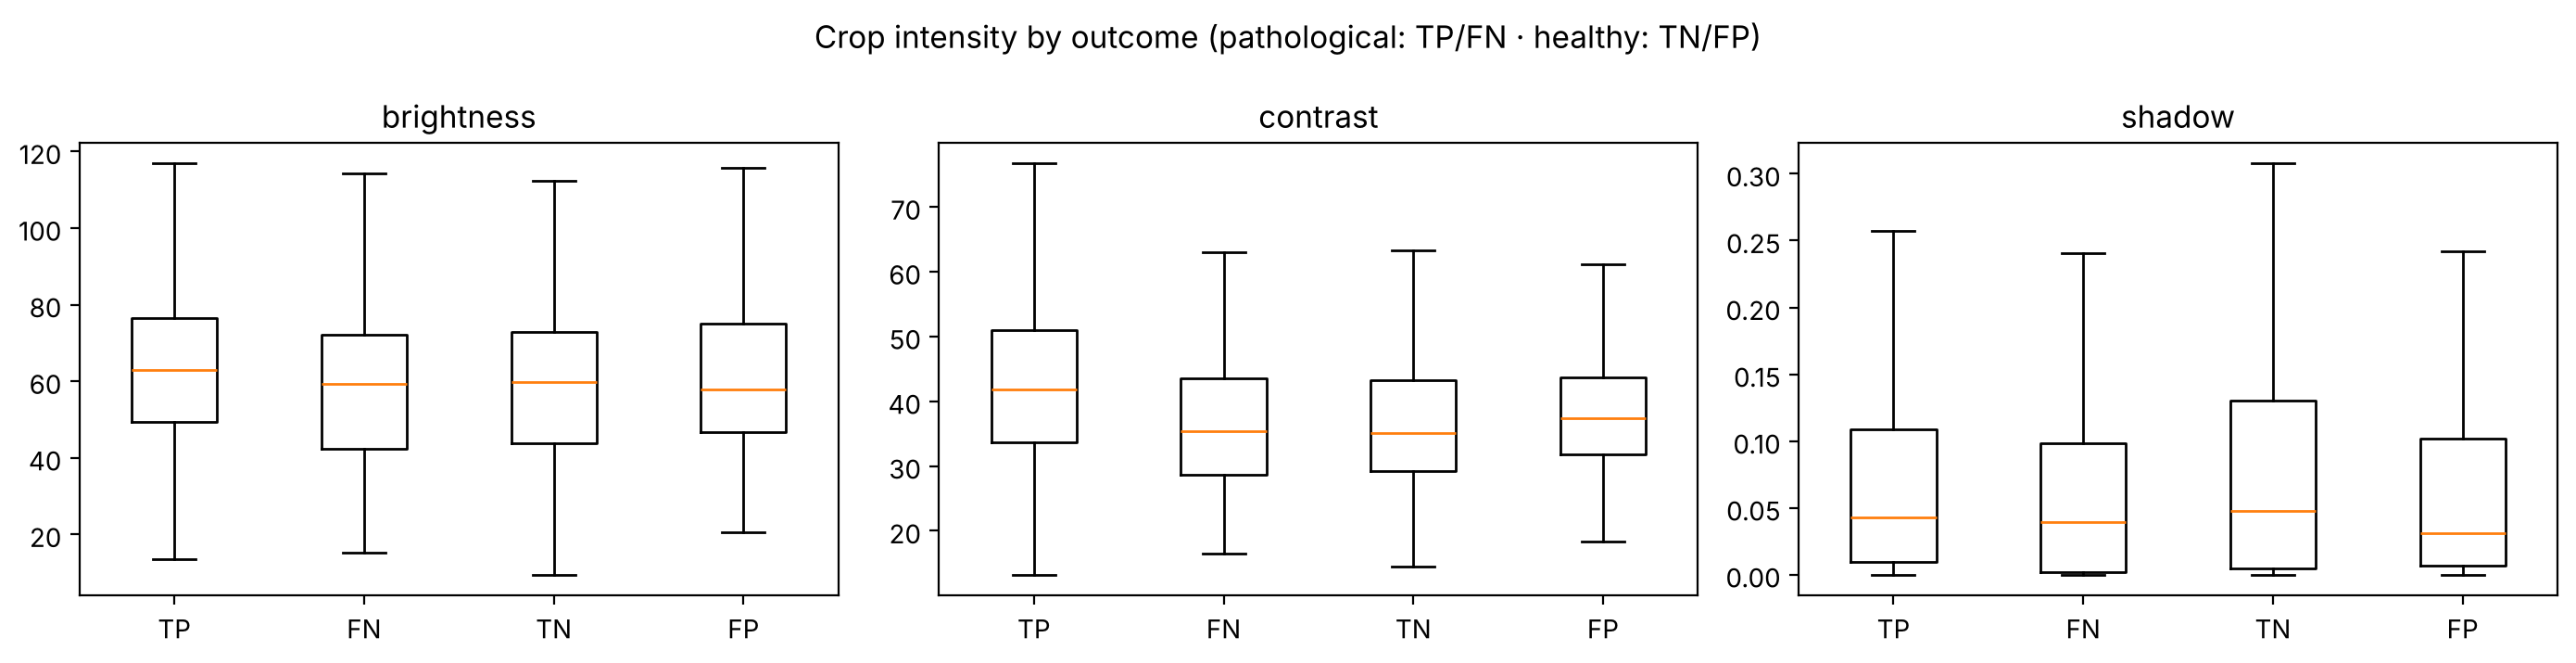

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
order = ['TP','FN','TN','FP']
for ax, col in zip(axs, ['brightness','contrast','shadow']):
    ax.boxplot([df.loc[df.outcome == o, col] for o in order], tick_labels=order, showfliers=False)
    ax.set_title(col)
fig.suptitle('Crop intensity by outcome (pathological: TP/FN · healthy: TN/FP)')
fig.tight_layout(); fig.savefig(OUT / 'intensity_by_outcome.png', dpi=150); plt.show()

Error rate in three equal groups (low / medium / high) of each measure:

In [12]:
res = []
for col in ['brightness','contrast','shadow']:
    for lbl, name, err in [(1,'pathological','FN'),(0,'healthy','FP')]:
        d = df[df.true_label == lbl].copy()
        d['tercile'] = pd.qcut(d[col].rank(method='first'), 3, labels=['low','medium','high'])
        r = d.groupby('tercile', observed=True).outcome.apply(lambda s: (s == err).mean())
        res.append(pd.Series(r.values, index=r.index, name=f'{col} · {name} ({err} rate)'))
terc = pd.DataFrame(res).round(3)
terc.to_csv(OUT / 'error_rate_by_intensity_tercile.csv'); terc

tercile,low,medium,high
brightness · pathological (FN rate),0.131,0.094,0.092
brightness · healthy (FP rate),0.413,0.527,0.480
contrast · pathological (FN rate),0.160,0.100,0.057
contrast · healthy (FP rate),0.387,0.507,0.527
shadow · pathological (FN rate),0.129,0.076,0.111
shadow · healthy (FP rate),0.480,0.527,0.413


**Low contrast** is the factor with the biggest effect: 16% of pathological kidneys are missed in the low-contrast group vs 6% in the high one. Brightness matters a little (13% vs 9%) and shadow not at all. False positives (39–53%) show no pattern.

## 7. Conflicting labels (p4-t2)

Near-identical images (same image or consecutive frames) with different diagnoses.

In [13]:
dup = pd.read_csv(ROOT / 'results/eda/duplicate_pairs.csv')
dup = dup[dup.verdict.isin(['identical image','same exam (consecutive frame)'])]
conf = dup[dup.diag_a != dup.diag_b][['img_a','img_b','verdict','diag_a','diag_b']]
o = df.set_index('image_id')
for s in 'ab':
    conf[f'prob_{s}']    = conf[f'img_{s}'].map(o.probability).round(3)
    conf[f'outcome_{s}'] = conf[f'img_{s}'].map(o.outcome)
conf.to_csv(OUT / 'conflicting_label_pairs.csv', index=False)
conflict_ids = set(conf.img_a) | set(conf.img_b)
print(len(conf), 'conflicting pairs ·',
      df[df.image_id.isin(conflict_ids) & df.error].shape[0], 'of', df.error.sum(), 'errors involve them')
conf

2 conflicting pairs · 1 of 375 errors involve them


,img_a,img_b,verdict,diag_a,diag_b,prob_a,outcome_a,prob_b,outcome_b
21,4,296,identical image,1,0,0.988,TP,0.989,FP
93,296,297,same exam (consecutive frame),0,1,0.989,FP,0.990,TP


Both pairs involve image **296**: labelled healthy, but identical to 4 and a consecutive frame of 297, both pathological. The model gives all three ≈0.99, so the FP on 296 is most likely a **labelling mistake**. It affects 1 of 375 errors.

## 8. Where the model looks: Grad-CAM (Phase 3)

We use the Grad-CAM metrics of the fold model that made each prediction, so they match the predictions we audit. (Phase 3 also reports a 5-model ensemble, but four of those models saw each image in training.)

In [14]:
xai = pd.read_csv(P3 / 'xai_metrics.csv')
XAI = {'single_gt_bin_contain': 'kidney_focus', 'single_peak_in_gt_kidney': 'peak_in_kidney',
       'single_pointing_hit_any': 'peak_on_lesion', 'single_pointing_hit_tol10': 'peak_near_lesion',
       'single_lesion_union_iou': 'lesion_overlap'}
df = df.merge(xai[['image_id', *XAI]].rename(columns=XAI), on='image_id')
df['empty_map'] = df.kidney_focus.isna()
df.loc[df.empty_map, 'peak_in_kidney'] = np.nan

def xai_summary(d):
    return pd.Series({
        'n': len(d),
        'empty maps': int(d.empty_map.sum()),
        'kidney focus (%)': 100 * d.kidney_focus.mean(),
        'peak in kidney (%)': 100 * d.peak_in_kidney.mean(),
        'images with lesion boxes': int(d.peak_on_lesion.notna().sum()),
        'peak on lesion (%)': 100 * d.peak_on_lesion.mean(),
        'peak within 10 px of lesion (%)': 100 * d.peak_near_lesion.mean(),
        'lesion overlap (IoU)': d.lesion_overlap.mean()})
xai_by_outcome = df.groupby('outcome').apply(xai_summary, include_groups=False).loc[['TP','FN','TN','FP']].round(2)
xai_by_outcome.to_csv(OUT / 'gradcam_by_outcome.csv'); xai_by_outcome

,n,empty maps,kidney focus (%),peak in kidney (%),images with lesion boxes,peak on lesion (%),peak within 10 px of lesion (%),lesion overlap (IoU)
outcome,,,,,,,,
TP,1373.0,0.0,87.57,91.99,1191.0,56.00,69.10,0.30
FN,162.0,15.0,21.78,21.77,132.0,8.33,10.61,0.03
TN,237.0,29.0,16.33,15.87,0.0,NaN,NaN,NaN
FP,213.0,0.0,75.84,81.69,0.0,NaN,NaN,NaN


- **TP:** attention on the kidney (peak inside in 92%) and on the lesion (peak within 10 px in 69%).
- **FN:** the model does not look at the lesion (peak near it in only 11%), and 15 maps are empty.
- **FP:** the model **does look at the kidney** (peak inside in 82%). It takes something inside a healthy kidney for a lesion, rather than being distracted by the background.

How often the attention finds each lesion type (one row per lesion box):

In [15]:
les = pd.read_csv(P3 / 'xai_lesion_level_metrics.csv')
les = les[les['mode'] == 'single_fold']
by_les_xai = (les.assign(lesion=les.lesion_class.map(CLASS_NAMES))
                 .groupby('lesion').agg(boxes=('pointing_hit', 'size'),
                                        peak_on_lesion_pct=('pointing_hit', 'mean'),
                                        peak_within_10px_pct=('pointing_hit_tol10', 'mean')))
by_les_xai[['peak_on_lesion_pct','peak_within_10px_pct']] *= 100
by_les_xai = by_les_xai.sort_values('peak_within_10px_pct').round(1)
by_les_xai.to_csv(OUT / 'gradcam_by_lesion_class.csv'); by_les_xai

,boxes,peak_on_lesion_pct,peak_within_10px_pct
lesion,,,
CE (cortex eschar),45,4.4,11.1
CT (cortex thinning),111,9.0,14.4
PYR (pyramids),384,14.3,24.7
ANG (angiomyolipoma),34,14.7,26.5
LIT (stone),110,16.4,29.1
SCY (simple cyst),1073,22.3,35.1
SRM (solid renal mass),11,36.4,36.4
CCY (complicated cyst),92,42.4,53.3
HYD (hydronephrosis),618,57.3,64.7


Hydronephrosis (65%) and complicated cysts (53%) are found most easily; thin or small findings such as cortex eschar (11%), cortex thinning (14%), pyramids (25%) and angiomyolipoma (26%) are rarely hit.

### Grad-CAM by view and by crop quality (p4-t2)

In [16]:
seg_by_view = df.groupby('view').agg(images=('image_id', 'size'), mean_dice=('dice', 'mean'),
                                     median_dice=('dice', 'median'),
                                     pct_dice_below_080=('dice', lambda s: 100 * (s < 0.80).mean())).round(3)
seg_by_view.to_csv(OUT / 'segmentation_quality_by_view.csv'); seg_by_view

,images,mean_dice,median_dice,pct_dice_below_080
view,,,,
0,1842,0.926,0.946,4.180
1,143,0.886,0.906,8.392


Segmentation is weaker in **view 1** (mean Dice 0.886 vs 0.926; 8.4% vs 4.2% poor crops). The transverse-view drop seen in the segmentation notebook was on the external KidneyUS data, which has no pathology labels.

In [17]:
def focus(d):
    return pd.Series({'n': len(d),
                      'kidney focus (%)': 100 * d.kidney_focus.mean(),
                      'peak in kidney (%)': 100 * d.peak_in_kidney.mean(),
                      'peak within 10 px of lesion (%)': 100 * d.peak_near_lesion.mean()})
sub = df[df.outcome.isin(['TP','FN','FP'])]
focus_view = sub.groupby(['view','outcome']).apply(focus, include_groups=False).round(1)
focus_dice = sub.groupby(['dice_group','outcome'], observed=True).apply(focus, include_groups=False).round(1)
focus_view.to_csv(OUT / 'gradcam_by_view.csv'); focus_dice.to_csv(OUT / 'gradcam_by_crop_dice.csv')
display(focus_view); display(focus_dice)

n  kidney focus (%)  peak in kidney (%)  peak within 10 px of lesion (%)
view outcome                                                                               
0    FN        153.0              22.4                22.5                             10.5
     FP        193.0              76.4                81.9                              NaN
     TP       1293.0              87.8                92.0                             68.4
1    FN          9.0              11.7                11.1                             12.5
     FP         20.0              70.1                80.0                              NaN
     TP         80.0              84.4                91.2                             80.0

n  kidney focus (%)  peak in kidney (%)  peak within 10 px of lesion (%)
dice_group outcome                                                                              
<0.80      FN         6.0              53.8                60.0                             25.0
           FP         3.0              58.9                66.7                              NaN
           TP        76.0              76.5                88.2                             74.2
0.80–0.90  FN        19.0              15.7                12.5                             15.4
           FP        28.0              60.4                71.4                              NaN
           TP       257.0              89.5                93.4                             70.6
0.90–0.95  FN        50.0              23.1                24.4                             10.8
           FP        74.0              80.8                87.8                              NaN
           TP       513.0              87.8                92.2                             68.0
≥0.95      FN        87.0              20.2                19.8                              9.0
           FP       108.0              76.9                80.6                              NaN
           TP       527.0              88.1                91.7                             68.8

The model looks at the kidney equally in both views (TP peak in kidney 91% vs 92%). Only the poorest crops (Dice < 0.80) make the attention less focused on the kidney (77% vs 88–90%), but the peak is still near the lesion in 74% of those TPs. **Segmentation problems do not change where the model looks in a meaningful way.**

Grad-CAM for the conflicting images 4, 296 and 297:

In [18]:
conf_xai = df[df.image_id.isin([4, 296, 297])][['image_id','true_label','probability','outcome','n_lesions',
                                                 'kidney_focus','peak_in_kidney','peak_near_lesion']].round(3)
conf_xai.to_csv(OUT / 'gradcam_conflicting_images.csv', index=False); conf_xai

,image_id,true_label,probability,outcome,n_lesions,kidney_focus,peak_in_kidney,peak_near_lesion
1204,296,0,0.989,FP,0,0.804,1.0,NaN
1205,297,1,0.990,TP,1,0.977,1.0,0.0
1319,4,1,0.988,TP,0,0.782,1.0,NaN


The model sees the same thing in all three (probability ≈0.99, peak inside the kidney), so the different label of 296 is a labelling question, not a model problem.

## 9. Success vs. failure cases (p4-t3)

Left: full image (cyan = crop, red = lesions). Right: crop with Grad-CAM (star = peak). Successes are TPs with a good crop (Dice ≥ 0.95) and the peak on a lesion, and very confident TNs; failures are the most confident errors, the worst crops and the conflicting pair.

In [19]:
import warnings; warnings.filterwarnings("ignore")
import torch, timm, torch.nn as nn
import torchvision.transforms as T

class PercentileNormalize:
    def __call__(self, img):
        a = np.asarray(img.convert('RGB'), dtype=np.float32)
        lo, hi = np.percentile(a, [1, 99])
        a = np.clip((a - lo) / max(hi - lo, 1e-6), 0, 1)
        return Image.fromarray((a * 255).astype(np.uint8))
EVAL_TF = T.Compose([PercentileNormalize(), T.Resize((224, 224)), T.ToTensor()])

def load_fold(k):
    ckpt = torch.load(P2 / f'nb06crops_weighted/imagenet/fold_{k}.pt', map_location='cpu', weights_only=False)
    m = timm.create_model('efficientnet_b0', pretrained=False, num_classes=2)
    m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(1280, 2))
    m.load_state_dict(ckpt['model_state_dict'])
    return m.eval()
MODELS = {k: load_fold(k) for k in range(5)}

def gradcam(model, x):
    store = {}
    def hook(_, __, out):
        store['feats'] = out
        out.register_hook(lambda g: store.__setitem__('grads', g))
    h = model.conv_head.register_forward_hook(hook)
    model.zero_grad()
    model(x)[:, 1].sum().backward()
    h.remove()
    w = store['grads'].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * store['feats']).sum(dim=1, keepdim=True))
    cam = nn.functional.interpolate(cam, size=(224, 224), mode='bilinear', align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().numpy()

def crop_cam(r):
    crop = Image.open(ROOT / f'oof_kidney_crops/{r.image_id}.jpg')
    cam = gradcam(MODELS[int(r.fold)], EVAL_TF(crop).unsqueeze(0))
    cam = np.asarray(Image.fromarray(cam.astype(np.float32)).resize(crop.size, Image.BILINEAR))
    return crop, cam

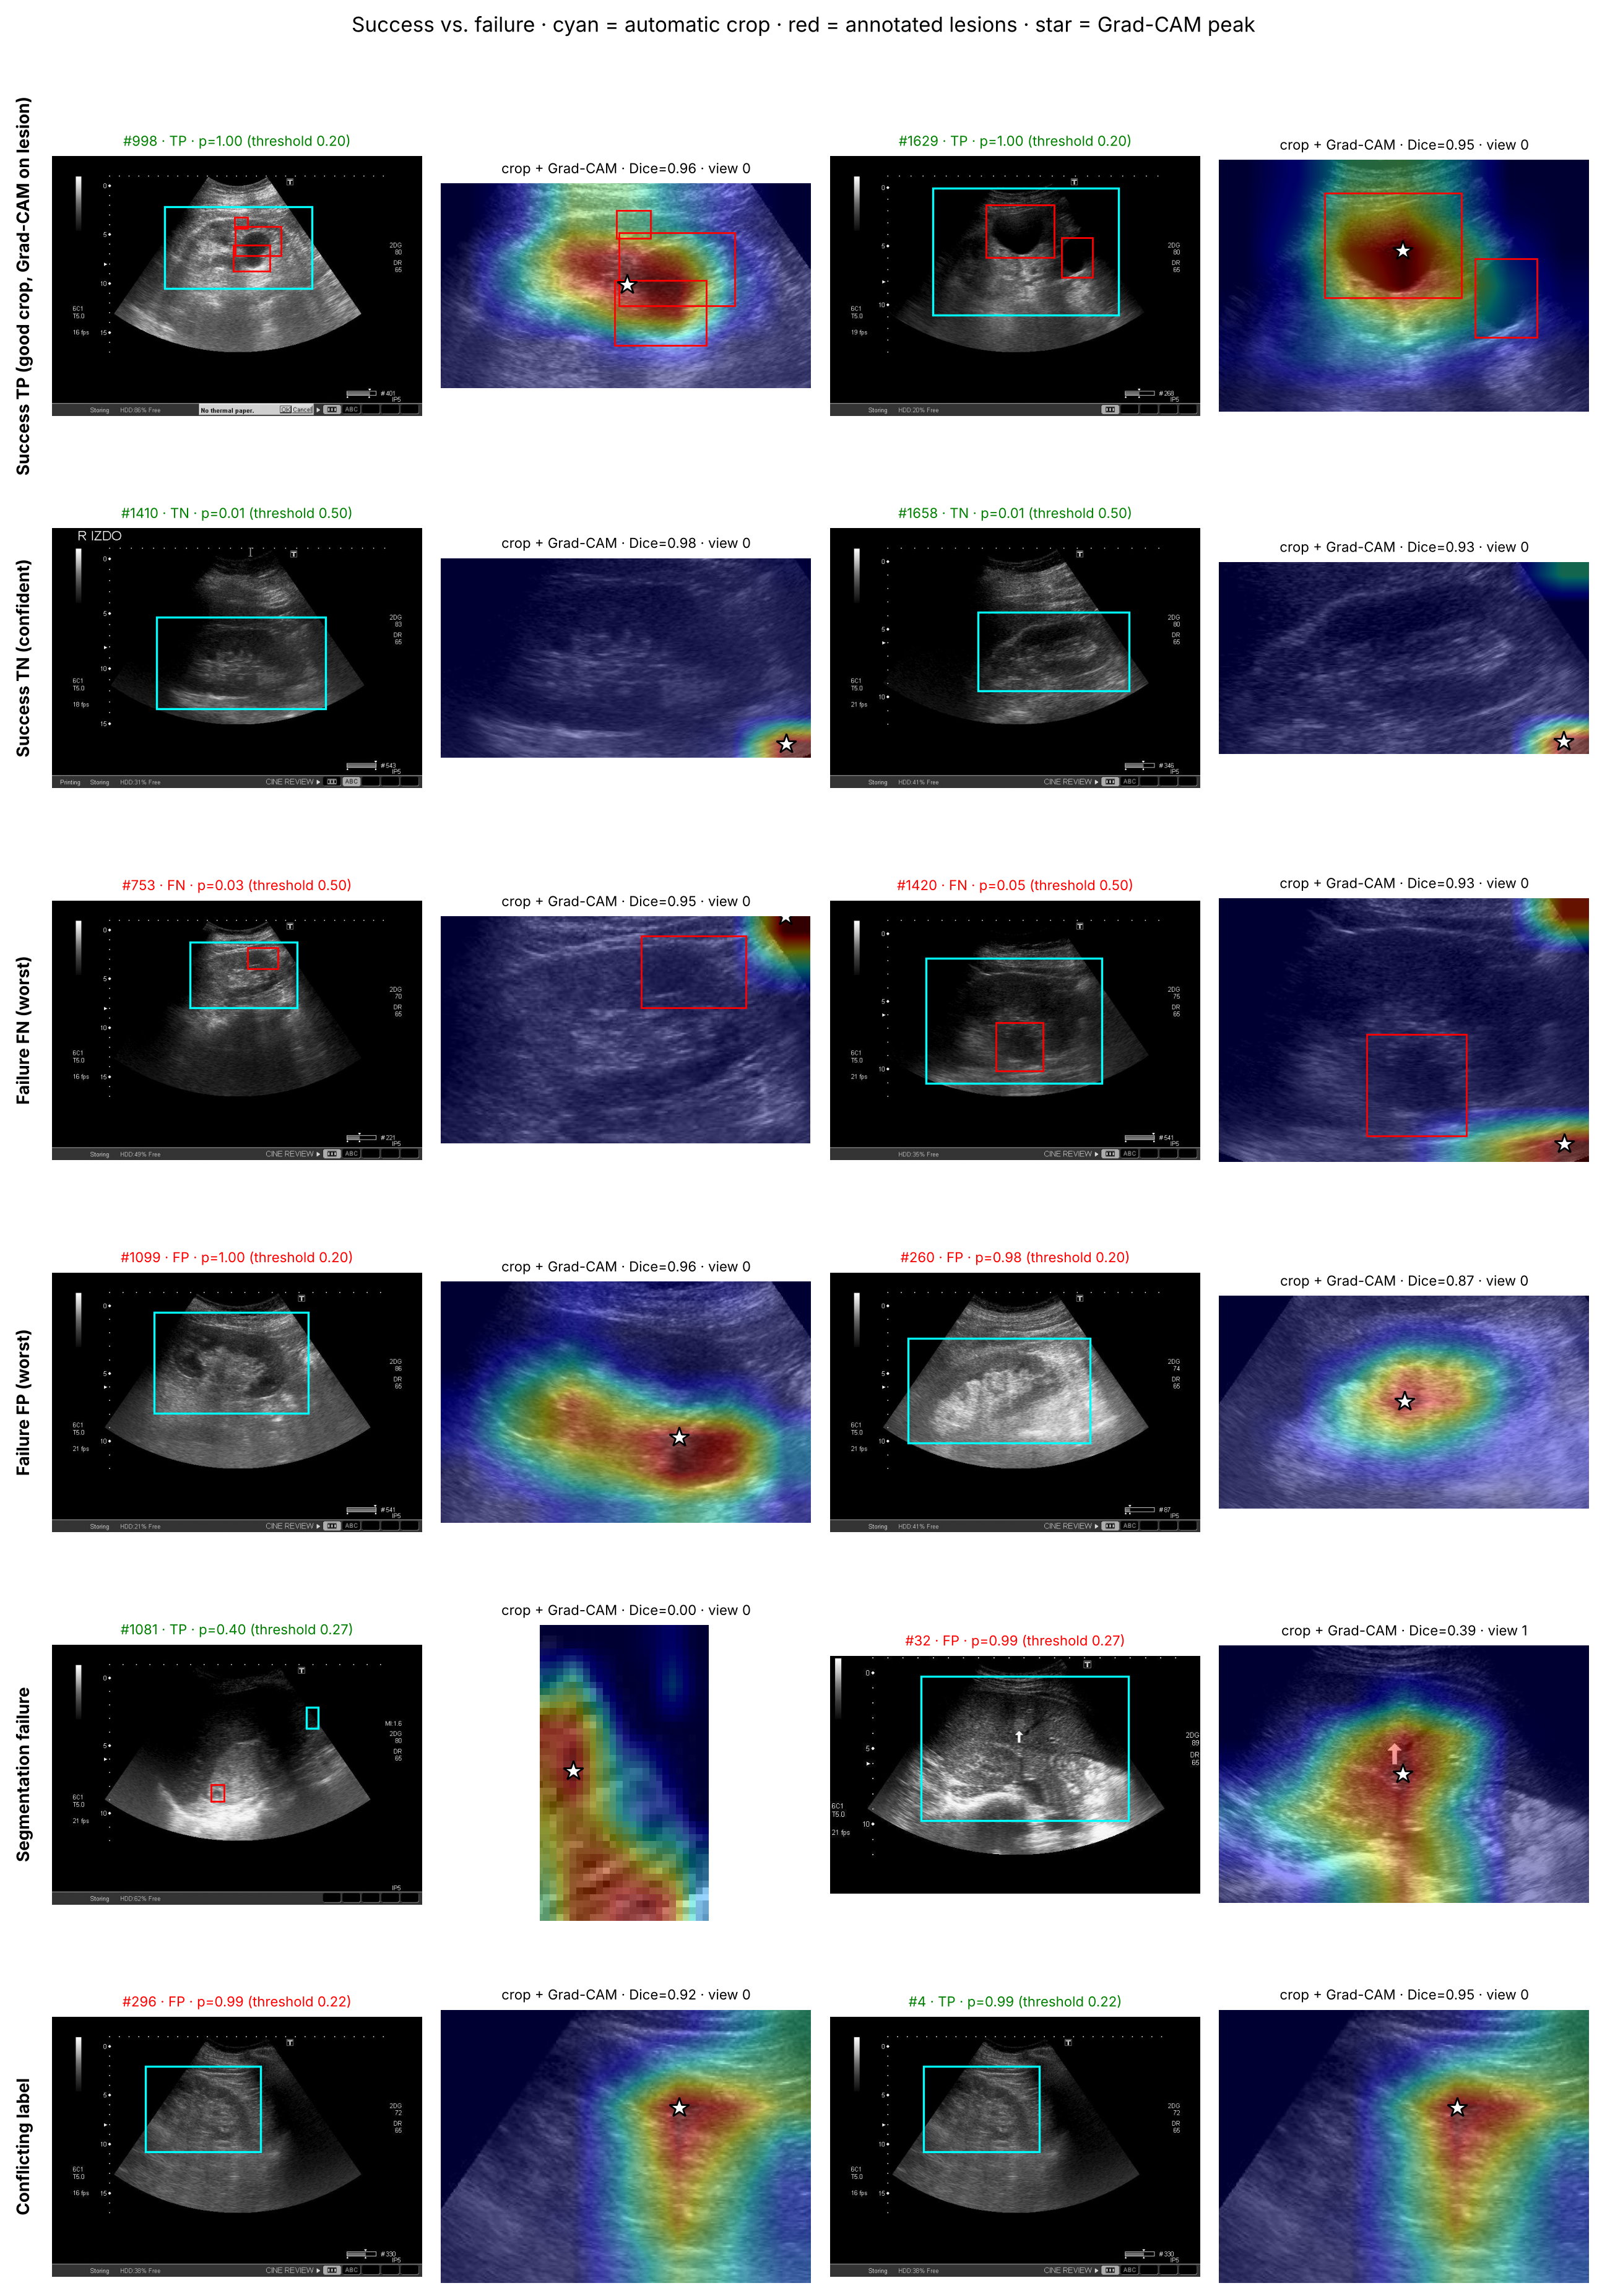

In [20]:
def show_case(ax_full, ax_crop, r):
    im = Image.open(ROOT / f'bbdd_kidney/images/{r.filename}').convert('L')
    _, boxes = parse_label(ROOT / f'bbdd_kidney/labels/{r.image_id}.txt')
    x0, y0, x1, y1 = r.crop_x0, r.crop_y0, r.crop_x1, r.crop_y1
    ax_full.imshow(im, cmap='gray')
    ax_full.add_patch(plt.Rectangle((x0, y0), x1-x0, y1-y0, fill=False, ec='cyan', lw=1.2))
    for x, y, w, h, c in boxes:
        ax_full.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec='red', lw=1))
    crop, cam = crop_cam(r)
    ax_crop.imshow(crop.convert('L'), cmap='gray')
    if cam.max() > 0:
        ax_crop.imshow(cam, cmap='jet', alpha=0.4, vmin=0, vmax=1)
        py, px = np.unravel_index(np.argmax(cam), cam.shape)
        ax_crop.plot(px, py, marker='*', color='white', markersize=12, markeredgecolor='black')
    for x, y, w, h, c in boxes:
        ax_crop.add_patch(plt.Rectangle((x - x0, y - y0), w, h, fill=False, ec='red', lw=1))
    ax_crop.set_xlim(0, crop.size[0]); ax_crop.set_ylim(crop.size[1], 0)
    col = 'green' if r.outcome in ('TP','TN') else 'red'
    ax_full.set_title(f'#{r.image_id} · {r.outcome} · p={r.probability:.2f} (threshold {r.threshold:.2f})', fontsize=8, color=col)
    ax_crop.set_title(f'crop + Grad-CAM · Dice={r.dice:.2f} · view {r.view}', fontsize=8)
    for a in (ax_full, ax_crop): a.axis('off')

picks = {
    'Success TP (good crop, Grad-CAM on lesion)': df[(df.outcome == 'TP') & (df.dice >= 0.95) & (df.peak_on_lesion == 1)].nlargest(2, 'margin'),
    'Success TN (confident)': df[df.outcome == 'TN'].nsmallest(2, 'margin'),
    'Failure FN (worst)':     df[df.outcome == 'FN'].nsmallest(2, 'margin'),
    'Failure FP (worst)':     df[df.outcome == 'FP'].nlargest(2, 'margin'),
    'Segmentation failure':   df.nsmallest(2, 'dice'),
    'Conflicting label':      df[df.image_id.isin([4, 296])],
}
fig, axs = plt.subplots(len(picks), 4, figsize=(13, 3.1*len(picks)))
for i, (name, d) in enumerate(picks.items()):
    for j, (_, r) in enumerate(d.head(2).iterrows()):
        show_case(axs[i, 2*j], axs[i, 2*j+1], r)
    axs[i, 0].text(-0.05, 0.5, name, transform=axs[i, 0].transAxes, rotation=90, va='center', ha='right', fontsize=10, weight='bold')
fig.suptitle('Success vs. failure · cyan = automatic crop · red = annotated lesions · star = Grad-CAM peak', y=1.0)
fig.tight_layout(); fig.savefig(OUT / 'success_vs_failure_grid.png', dpi=150, bbox_inches='tight'); plt.show()

- **Successes:** the heat covers the lesion (image 1629) or the kidney stays cold (TN).
- **FN:** well-cropped kidneys, but the attention goes to the edge of the crop, far from the lesion.
- **FP:** the heat is in the middle of a healthy kidney (renal sinus area).
- **Segmentation failures:** 1081's crop is background; in 32 the peak falls on a white arrow drawn on the image.
- **296 vs 4:** same image, same map, opposite labels.

## 10. Error taxonomy

Each FP/FN (375 failures) gets **one** cause: the first rule that applies.
1. Conflicting label (duplicate pair with a different diagnosis)
2. Segmentation failure (Dice < 0.80) or lesion cut off by the crop
3. Minority view (view 1)
4. Small lesion (FN only, smallest 25% of lesions)
5. Dark, low-contrast or shadowed image (lowest 10% brightness/contrast or highest 10% shadow)
6. Borderline (probability within 0.05 of the threshold)
7. Normal kidney tissue taken for a lesion (FP, Grad-CAM peak inside the kidney)
8. Attention outside the kidney (FP, peak outside the kidney)
9. Lesion not looked at (FN, peak more than 10 px from every lesion, or empty map)
10. No evident cause

In [21]:
q_area = df.loc[df.true_label == 1, 'min_lesion_area'].quantile(0.25)
lo_b, lo_c, hi_s = df.brightness.quantile(0.10), df.contrast.quantile(0.10), df.shadow.quantile(0.90)
def cause(r):
    if r.image_id in conflict_ids:                                  return '1. Conflicting label'
    if r.dice < 0.80 or r.image_id in cut:                          return '2. Segmentation failure / lesion cut off'
    if r.view == 1:                                                 return '3. Minority view (view 1, longitudinal)'
    if r.outcome == 'FN' and r.min_lesion_area <= q_area:           return '4. Small lesion'
    if r.brightness <= lo_b or r.contrast <= lo_c or r.shadow >= hi_s: return '5. Dark / low contrast / shadow'
    if abs(r.margin) < 0.05:                                        return '6. Borderline (near threshold)'
    if r.outcome == 'FP' and r.peak_in_kidney == 1:                 return '7. Normal kidney tissue taken for a lesion'
    if r.outcome == 'FP':                                           return '8. Attention outside the kidney'
    if r.outcome == 'FN' and r.n_lesions > 0 and r.peak_near_lesion != 1: return '9. Lesion not looked at'
    return '10. No evident cause'
err = df[df.error].copy()
err['cause'] = err.apply(cause, axis=1)
tax = err.pivot_table(index='cause', columns='outcome', values='image_id', aggfunc='count', fill_value=0)
tax = tax.loc[sorted(tax.index, key=lambda s: int(s.split('.')[0]))]
tax['total'] = tax.sum(axis=1); tax['% of errors'] = (100 * tax.total / tax.total.sum()).round(1)
err[['image_id','outcome','probability','threshold','view','dice','brightness','contrast','shadow','peak_in_kidney','peak_near_lesion','cause']].to_csv(OUT / 'error_cases_with_cause.csv', index=False)
tax.to_csv(OUT / 'error_taxonomy.csv'); tax

outcome,FN,FP,total,% of errors
cause,,,,
1. Conflicting label,0,1,1,0.3
2. Segmentation failure / lesion cut off,11,3,14,3.7
"3. Minority view (view 1, longitudinal)",8,18,26,6.9
4. Small lesion,40,0,40,10.7
5. Dark / low contrast / shadow,30,39,69,18.4
6. Borderline (near threshold),6,11,17,4.5
7. Normal kidney tissue taken for a lesion,0,117,117,31.2
8. Attention outside the kidney,0,24,24,6.4
9. Lesion not looked at,49,0,49,13.1


Image and label causes (rules 1–6) explain 45% of errors. With Grad-CAM, the largest group is **117 FPs where the model takes normal kidney tissue for a lesion**, followed by **49 FNs where it does not look at the lesion**. Only 18 errors (5%) remain without a cause. Per-image causes are in `error_cases_with_cause.csv`.

## 11. Conclusions and clinical discussion

We audited the 375 mistakes made by our classifier (162 missed pathological kidneys and 213 false alarms on healthy kidneys) to understand **where and why it fails**. These are our main findings:

**1. The automatic crop is not the problem.**
One worry was that a bad crop of the kidney would make the classifier fail. This is not the case: when the crop is poor, the model still detects pathological kidneys just as well (sensitivity 0.93 vs 0.86 for the best crops). Only 14 of the 375 mistakes (3.7%) can be linked to a bad crop. This means the automatic pipeline from Phase 1 can be trusted.

**2. The model misses lesions that are hard to see.**
The pathological kidneys that the model calls healthy are mostly:
- **rare lesions**, such as solid renal mass (sensitivity 0.64) and angiomyolipoma (0.67), for which there are very few training examples;
- **small lesions** (sensitivity 0.87 for the smallest vs 0.94 for the largest);
- **low-contrast images**, where 16% of pathological kidneys are missed, compared with 6% in high-contrast images.

The Grad-CAM maps confirm this: in missed cases, the model almost never looks at the lesion (11% vs 69% when it gets it right). In other words, **it misses the lesion because it does not see it**.

**3. False alarms are the main weakness.**
The model only recognises 53% of healthy kidneys as healthy. This is partly a team decision: we chose a low threshold so that very few sick patients are missed. But the Grad-CAM maps show something important: in 82% of false alarms the model *is* looking inside the kidney. **It is not distracted by the background; it confuses normal kidney tissue with a lesion.** This is the largest group of errors (117 of 375, 31%).

**4. The view does not matter.**
Transverse and longitudinal images are classified equally well (sensitivity 0.89 vs 0.90), and the model looks at the kidney in the same way in both.

**5. Some labels are wrong.**
Images 4 and 296 are the same image, but one is labelled pathological and the other healthy. The model gives both (and image 297, from the same exam) a probability of 0.99. That "mistake" is a labelling error, not a model error.

**In summary:** with the Grad-CAM data, 357 of the 375 mistakes have a likely explanation. The model is reliable at finding clear lesions, but it struggles with small, rare or low-contrast ones, and it produces many false alarms by mistaking normal tissue for disease. The next steps should focus on **more examples of rare lesions** and on **reducing false alarms on healthy kidneys**.

### Clinical discussion
- At this threshold the model detects about 9 of 10 pathological kidneys but flags about half of the healthy ones, so it could only work as a first filter, not as a diagnosis.
- Missing solid renal masses matters most clinically, because they can be malignant; these cases need more training examples.
- The false positives should be reviewed with the clinicians to identify which normal structures the model confuses with lesions.
- Grad-CAM should not be shown as a lesion locator: even in correct detections the peak is on the lesion only about half of the time.
- All results are internal (one hospital, one scanner); there is no external test with pathology labels.